# Volcano Plot

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Scientific:* Domain-neutral statistics and research plots: effect sizes, meta-analysis, agreement, omics, replicates and visual inference.

## Design purpose

A scatter of effect size (log2 fold change) against statistical significance (−log10 p) for thousands of features at once. Hits that are both large and significant rise to the upper corners.

## When to use

- Show differential gene or protein expression (RNA-seq, proteomics, metabolomics)
- Show any mass univariate test where both effect size and p-value matter

## Avoid when

- There are only a few features (use a forest plot or table)
- There are no p-values (use an MA plot or rank plot)

## Alternatives

- MA plot
- Clustered heatmap of the top hits
- Ranked bar chart of fold changes

## Design tips

- Draw the fold-change and significance thresholds as thin reference lines
- Color only the significant up- and down-regulated features (two opposite hues) and leave the rest gray
- Label only the handful of top hits

## Example

Synthetic RNA-seq comparison of tumour versus normal tissue, 8,000 genes with about 4% truly changed.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy.stats import norm

### Data

In [2]:
rng = np.random.default_rng(21)
n = 8000
true_effect = np.zeros(n)
hits = rng.choice(n, 320, replace=False)
true_effect[hits] = rng.choice([-1, 1], 320) * rng.uniform(0.8, 3.5, 320)
se = rng.uniform(0.18, 0.45, n)
log2fc = true_effect + rng.normal(0, se)
p = 2 * norm.sf(np.abs(log2fc / se))
# Benjamini-Hochberg adjusted p-values
order = np.argsort(p)
ranked = p[order] * n / np.arange(1, n + 1)
padj = np.empty(n); padj[order] = np.minimum(1, np.minimum.accumulate(ranked[::-1])[::-1])
df = pd.DataFrame({"gene": [f"GENE{i:04d}" for i in range(n)], "log2fc": log2fc,
                   "p": p, "padj": padj})
df["status"] = np.select([(df.padj < 0.05) & (df.log2fc >= 1), (df.padj < 0.05) & (df.log2fc <= -1)],
                         ["Up", "Down"], "NS")
df["nlp"] = -np.log10(df.p)
df.status.value_counts()

status
NS      7712
Down     151
Up       137
Name: count, dtype: int64

### Plot

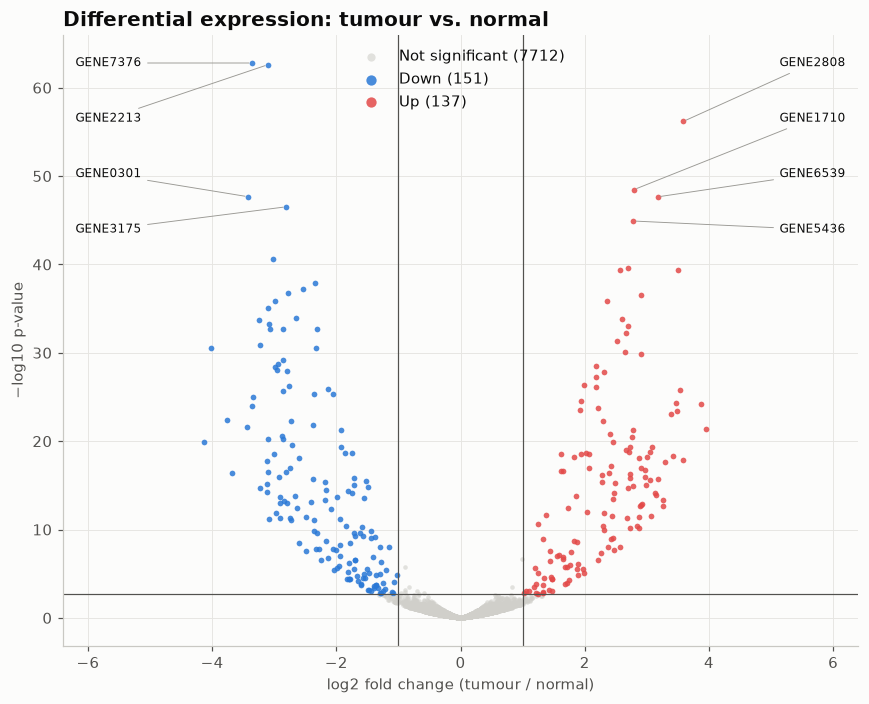

In [3]:
colors = {"NS": "#d0cfca", "Up": PALETTE[7], "Down": PALETTE[0]}
fig, ax = plt.subplots(figsize=(8, 6.5))
for status in ["NS", "Down", "Up"]:
    d = df[df.status == status]
    ax.scatter(d.log2fc, d.nlp, s=9 if status == "NS" else 14, color=colors[status],
               alpha=0.6 if status == "NS" else 0.85, linewidth=0,
               label=f"{status} ({len(d)})" if status != "NS" else f"Not significant ({len(d)})")
thr = df.loc[df.padj < 0.05, "nlp"].min()
ax.axhline(thr, color="#52514e", linewidth=0.8)
for v in (-1, 1):
    ax.axvline(v, color="#52514e", linewidth=0.8)
ymax = df.nlp.max()
for side, status in [(1, "Up"), (-1, "Down")]:
    top = df[df.status == status].nlargest(4, "nlp")
    for (_, r), ty in zip(top.iterrows(), np.linspace(ymax, ymax * 0.7, 4)):
        ax.annotate(r.gene, (r.log2fc, r.nlp), xytext=(side * 6.2, ty), textcoords="data",
                    ha="right" if side > 0 else "left", va="center", fontsize=8, color="#0b0b0b",
                    arrowprops=dict(arrowstyle="-", color="#9a9994", linewidth=0.6))
ax.set_xlim(-6.4, 6.4)
ax.set_xlabel("log2 fold change (tumour / normal)")
ax.set_ylabel("−log10 p-value")
ax.set_title("Differential expression: tumour vs. normal")
ax.legend(loc="upper center", markerscale=1.8)
fig.tight_layout()
plt.show()

## How to read it

Genes in the upper right are strongly up-regulated and highly significant, and those in the upper left are down-regulated. Gray genes fail the FDR < 0.05 or |log2FC| ≥ 1 cut-off.

---
Standalone script: [`volcano_plot.py`](volcano_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)